In [1]:
from maxent_insect_dir import config
import pathlib
import geopandas as gpd
import rasterio.plot as rioplot # To Visualize Raster Data
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import os


pd.options.mode.chained_assignment = None  # default='warn'

In [2]:
config.Insect_list

{'Brown_Marmorated_Stink_bug': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/Species Data/Guna/EDD Maps Site/Brown_Marmorated_Stink_Bug - (Halyomorpha_halys) (1999_2023).gpkg'),
 'Corn_Earworm': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/Species Data/Guna/EDD Maps Site/Corn_Earworm - (Helicoverpa_Zea) (2004-2023).gpkg'),
 'Large_Lady_Beetle': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/Species Data/Guna/EDD Maps Site/Large_Lady_Beetle - (Harmonia_Axyridis) (1995-2023).gpkg'),
 'Brown_Marmorated_Stink_bug_2': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/Species Data/Guna/GBIF Site/Brown_Marmorated_Stink_Bug -  (Halyomorpha_halys) (2007-2023).gpkg'),
 'Root_Weevil': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/Species Data/Guna/GBIF Site/Root_Weevil - (Diaprepes_abbreviatus) (2012-2023).gpkg')}

In [47]:
INSECT_NAME = 'Root_Weevil'
INSECT_DATA = config.config_['insect']['GBIF'][INSECT_NAME]
PATH_SAVE_FIG = config.PATH_TO_SAVE_INITIAL_DATA_VIS_INSECT

# Load the data

In [48]:
# Define function to read GeoDataFrame with exception handling
def safe_read_file(file_path, layer_name=None):
    try:
        if layer_name:
            return gpd.read_file(file_path, layer=layer_name)
        else:
            return gpd.read_file(file_path)
    except UnicodeDecodeError:
        print(f"Unicode decoding error occurred while reading layer '{layer_name}' from {file_path}. Attempting with ISO-8859-1 encoding.")
        try:
            if layer_name:
                return gpd.read_file(file_path, layer=layer_name, encoding='ISO-8859-1')
            else:
                return gpd.read_file(file_path, encoding='ISO-8859-1')
        except Exception as e:
            print(f"Failed to read layer '{layer_name}' from {file_path}: {e}")
            return None
    except Exception as e:
        print(f"An error occurred while reading layer '{layer_name}' from {file_path}: {e}")
        return None

In [49]:
# Load the presence data
presence = safe_read_file(INSECT_DATA)

In [50]:
presence.head()

,scientific,locality,occurrence,latitude,longitude,day,month,Year,geometry
0,"Diaprepes abbreviatus (Linnaeus""",US,Florida,26.082689,-80.237779,2023-06-13T14:26:00,13,2023,POINT (-80.23778 26.08269)
1,"Diaprepes abbreviatus (Linnaeus""",US,Florida,28.813627,-81.324068,2017-07-16T21:08:14,16,2017,POINT (-81.32407 28.81363)
2,"Diaprepes abbreviatus (Linnaeus""",US,Texas,29.755168,-95.417309,2023-06-13T14:25:09,13,2023,POINT (-95.41731 29.75517)
3,"Diaprepes abbreviatus (Linnaeus""",US,Texas,29.958864,-95.562072,2023-06-12T16:13:37,12,2023,POINT (-95.56207 29.95886)
4,"Diaprepes abbreviatus (Linnaeus""",US,Texas,29.584945,-95.031163,2023-06-11T14:35:33,11,2023,POINT (-95.03116 29.58494)


In [51]:
presence.columns

Index(['scientific', 'locality', 'occurrence', 'latitude', 'longitude', 'day',
       'month', 'Year', 'geometry'],
      dtype='object')

In [53]:
# Drop the 'Unnamed_ 0' column 
# presence = presence.drop(['Unnamed_ 0'], axis = 1)

In [38]:
presence.head(2)

,species,occurrence,latitude,longitude,day,month,Year,speciesKey,geometry
0,Halyomorpha halys,California,34.016747,-118.287683,2014-03-13T00:00:00,13.0,2014.0,4485843.0,POINT (-118.28768 34.01675)
1,Halyomorpha halys,Pennsylvania,40.518756,-79.807043,2014-03-30T09:31:31,30.0,2014.0,4485843.0,POINT (-79.80704 40.51876)


In [54]:
# The month column is wrong. The month column contain the date. Their is no month value in the data, but can be extracted from the day column

# Convert the 'day' column to datetime format
presence['day'] = pd.to_datetime(presence['day'])

# Extract day, month, and year into separate columns
presence['Year'] = presence['day'].dt.year
presence['month'] = presence['day'].dt.month
presence['day_number'] = presence['day'].dt.day

In [55]:
presence.head()

,scientific,locality,occurrence,latitude,longitude,day,month,Year,geometry,day_number
0,"Diaprepes abbreviatus (Linnaeus""",US,Florida,26.082689,-80.237779,2023-06-13 14:26:00,6,2023,POINT (-80.23778 26.08269),13
1,"Diaprepes abbreviatus (Linnaeus""",US,Florida,28.813627,-81.324068,2017-07-16 21:08:14,7,2017,POINT (-81.32407 28.81363),16
2,"Diaprepes abbreviatus (Linnaeus""",US,Texas,29.755168,-95.417309,2023-06-13 14:25:09,6,2023,POINT (-95.41731 29.75517),13
3,"Diaprepes abbreviatus (Linnaeus""",US,Texas,29.958864,-95.562072,2023-06-12 16:13:37,6,2023,POINT (-95.56207 29.95886),12
4,"Diaprepes abbreviatus (Linnaeus""",US,Texas,29.584945,-95.031163,2023-06-11 14:35:33,6,2023,POINT (-95.03116 29.58494),11


In [56]:
presence.describe()

,latitude,longitude,day,month,Year,day_number
count,1231.000000,1231.000000,1231,1231.000000,1231.000000,1231.000000
mean,27.788340,-85.076016,2021-02-23 09:02:08.970755328,6.746548,2020.627945,16.028432
min,17.974567,-118.147760,2009-03-30 10:18:00,1.000000,2009.000000,1.000000
25%,26.341025,-90.176280,2020-05-11 14:13:15,5.000000,2020.000000,9.000000
50%,28.533085,-82.002435,2021-08-15 15:24:54,7.000000,2021.000000,16.000000
75%,29.857861,-80.379234,2022-07-29 11:06:48,9.000000,2022.000000,24.000000
max,33.787781,-65.678963,2023-06-13 14:26:00,12.000000,2023.000000,31.000000
std,3.661797,11.225435,NaN,2.848323,1.931257,8.706507


In [57]:
presence.describe(include='object')

,scientific,locality,occurrence
count,1231,1231,1231
unique,1,3,50
top,"Diaprepes abbreviatus (Linnaeus""",US,Florida
freq,1231,1107,752


In [58]:
# Add explicit label to the data
presence['label'] = 1 # Here i am assuming that its only presence only data. No undected sample here.

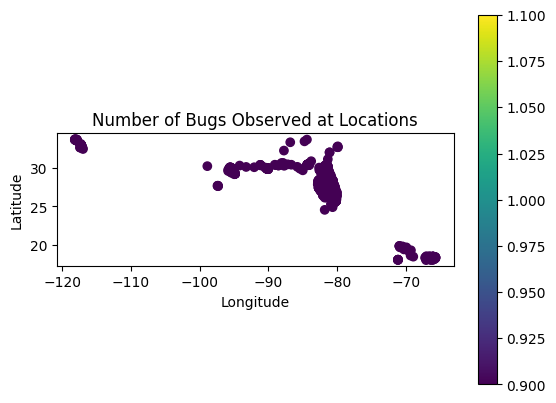

In [59]:
# Plot the points, with size corresponding to the number of bugs observed
presence.plot(marker='o', column='label', cmap='viridis', legend=True)
plt.title("Number of Bugs Observed at Locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.savefig(os.path.join(PATH_SAVE_FIG, INSECT_NAME + '_map.png'))
plt.show()

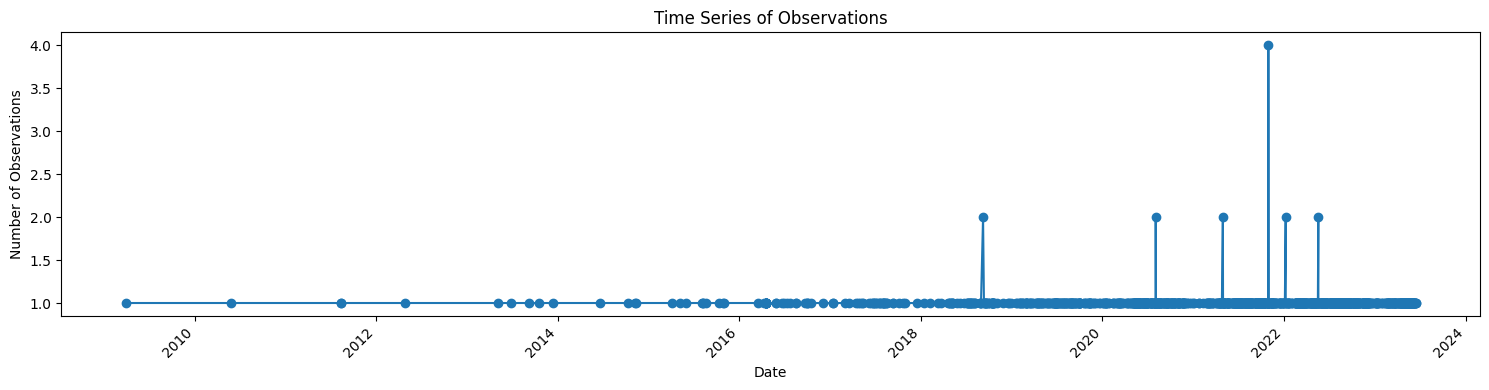

In [60]:
# Plotting a time series plot
plt.figure(figsize=(15, 4))

presence.groupby('day').size().sort_index().plot(kind='line', marker='o')

plt.title('Time Series of Observations')
plt.xlabel('Date')
plt.ylabel('Number of Observations')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(PATH_SAVE_FIG, INSECT_NAME + '_timeline.png'))
plt.show()